In [187]:
# Basic packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data splitting and cross-validation
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score

# Preprocessing and pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Linear models
from sklearn.linear_model import LinearRegression, Lasso, LassoCV

# Tree-based models
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

# Evaluation metrics
from sklearn.metrics import mean_squared_error, r2_score

# Statistical modeling
import statsmodels.api as sm

from sklearn.neighbors import KNeighborsRegressor

In [188]:
# Loading the dataset
data = pd.read_csv('house_prices.csv', index_col='Id')

# There are 79 features
data.drop('SalePrice', axis=1).shape[1]

79

In [189]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2908 entries, 1 to 2919
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     2908 non-null   int64  
 1   MSZoning       2905 non-null   object 
 2   LotFrontage    2422 non-null   float64
 3   LotArea        2908 non-null   int64  
 4   Street         2908 non-null   object 
 5   Alley          197 non-null    object 
 6   LotShape       2908 non-null   object 
 7   LandContour    2908 non-null   object 
 8   Utilities      2906 non-null   object 
 9   LotConfig      2908 non-null   object 
 10  LandSlope      2908 non-null   object 
 11  Neighborhood   2908 non-null   object 
 12  Condition1     2908 non-null   object 
 13  Condition2     2908 non-null   object 
 14  BldgType       2908 non-null   object 
 15  HouseStyle     2908 non-null   object 
 16  OverallQual    2908 non-null   int64  
 17  OverallCond    2908 non-null   int64  
 18  YearBuilt    

In [190]:
# Calculate the percentage of missing values for each column
missing_percent = data.isnull().mean()

# Identify columns with more than 50% missing values
columns_to_drop = missing_percent[missing_percent >= 0.50].index

# Drop the identified columns
data_cleaned = data.drop(columns=columns_to_drop)

In [191]:
print("Dropped columns:")
print(list(columns_to_drop))

Dropped columns:
['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature']


In [192]:
# Fill missing values in numeric columns with the median
numeric_cols = data_cleaned.select_dtypes(include=["number"]).columns

# Fill missing values in numeric columns with the median
data_cleaned[numeric_cols] = data_cleaned[numeric_cols].fillna(data_cleaned[numeric_cols].median())

In [193]:
# Identify categorical columns
categorical_cols = data_cleaned.select_dtypes(include=["object", "category"]).columns

# Drop rows with missing values in categorical columns
# data_cleaned = data_cleaned.dropna(subset=categorical_cols)

categorical_cols = data_cleaned.select_dtypes(include=["object", "category"]).columns

data_cleaned = data_cleaned.drop(
    columns=data_cleaned[categorical_cols].columns[
        data_cleaned[categorical_cols].isnull().any()
    ]
)

In [194]:
data_cleaned

,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,Condition1,...,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,65.0,8450,Pave,Reg,Lvl,Inside,Gtl,CollgCr,Norm,...,61,0,0,0,0,0,2,2008,Normal,208500
2,20,80.0,9600,Pave,Reg,Lvl,FR2,Gtl,Veenker,Feedr,...,0,0,0,0,0,0,5,2007,Normal,181500
3,60,68.0,11250,Pave,IR1,Lvl,Inside,Gtl,CollgCr,Norm,...,42,0,0,0,0,0,9,2008,Normal,223500
4,70,60.0,9550,Pave,IR1,Lvl,Corner,Gtl,Crawfor,Norm,...,35,272,0,0,0,0,2,2006,Abnorml,140000
5,60,84.0,14260,Pave,IR1,Lvl,FR2,Gtl,NoRidge,Norm,...,84,0,0,0,0,0,12,2008,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2915,160,21.0,1936,Pave,Reg,Lvl,Inside,Gtl,MeadowV,Norm,...,0,0,0,0,0,0,6,2006,Normal,90500
2916,160,21.0,1894,Pave,Reg,Lvl,Inside,Gtl,MeadowV,Norm,...,24,0,0,0,0,0,4,2006,Abnorml,71000
2917,20,160.0,20000,Pave,Reg,Lvl,Inside,Gtl,Mitchel,Norm,...,0,0,0,0,0,0,9,2006,Abnorml,131000


In [195]:
data_cleaned = data_cleaned.reset_index(drop=True).copy()
data_cleaned

,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,Condition1,...,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleCondition,SalePrice
0,60,65.0,8450,Pave,Reg,Lvl,Inside,Gtl,CollgCr,Norm,...,61,0,0,0,0,0,2,2008,Normal,208500
1,20,80.0,9600,Pave,Reg,Lvl,FR2,Gtl,Veenker,Feedr,...,0,0,0,0,0,0,5,2007,Normal,181500
2,60,68.0,11250,Pave,IR1,Lvl,Inside,Gtl,CollgCr,Norm,...,42,0,0,0,0,0,9,2008,Normal,223500
3,70,60.0,9550,Pave,IR1,Lvl,Corner,Gtl,Crawfor,Norm,...,35,272,0,0,0,0,2,2006,Abnorml,140000
4,60,84.0,14260,Pave,IR1,Lvl,FR2,Gtl,NoRidge,Norm,...,84,0,0,0,0,0,12,2008,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2903,160,21.0,1936,Pave,Reg,Lvl,Inside,Gtl,MeadowV,Norm,...,0,0,0,0,0,0,6,2006,Normal,90500
2904,160,21.0,1894,Pave,Reg,Lvl,Inside,Gtl,MeadowV,Norm,...,24,0,0,0,0,0,4,2006,Abnorml,71000
2905,20,160.0,20000,Pave,Reg,Lvl,Inside,Gtl,Mitchel,Norm,...,0,0,0,0,0,0,9,2006,Abnorml,131000
2906,85,62.0,10441,Pave,Reg,Lvl,Inside,Gtl,Mitchel,Norm,...,32,0,0,0,0,700,7,2006,Normal,132000


In [196]:
data_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2908 entries, 0 to 2907
Data columns (total 58 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     2908 non-null   int64  
 1   LotFrontage    2908 non-null   float64
 2   LotArea        2908 non-null   int64  
 3   Street         2908 non-null   object 
 4   LotShape       2908 non-null   object 
 5   LandContour    2908 non-null   object 
 6   LotConfig      2908 non-null   object 
 7   LandSlope      2908 non-null   object 
 8   Neighborhood   2908 non-null   object 
 9   Condition1     2908 non-null   object 
 10  Condition2     2908 non-null   object 
 11  BldgType       2908 non-null   object 
 12  HouseStyle     2908 non-null   object 
 13  OverallQual    2908 non-null   int64  
 14  OverallCond    2908 non-null   int64  
 15  YearBuilt      2908 non-null   int64  
 16  YearRemodAdd   2908 non-null   int64  
 17  RoofStyle      2908 non-null   object 
 18  RoofMatl

In [197]:
# Define the target column
target_col = 'SalePrice' 

# Find categorical columns
cat_cols = data_cleaned.drop(columns=[target_col]).select_dtypes(
    include=['object', 'category']
).columns

# save for reference group
reference_groups = {}

for col in cat_cols:
    # Find the reference group (the most frequent category)
    ref = data_cleaned[col].mode(dropna=True)[0]
    reference_groups[col] = ref
    
    # Create a new category order with the reference group first
    categories = [ref] + [x for x in data_cleaned[col].dropna().unique() if x != ref]
    
    data_cleaned[col] = pd.Categorical(data_cleaned[col], categories=categories)

# One-hot encode categorical variables, dropping the first category to avoid multicollinearity
df_encoded = pd.get_dummies(
    data_cleaned,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

print("Reference groups:")
print(reference_groups)

print(df_encoded.head())

Reference groups:
{'Street': 'Pave', 'LotShape': 'Reg', 'LandContour': 'Lvl', 'LotConfig': 'Inside', 'LandSlope': 'Gtl', 'Neighborhood': 'NAmes', 'Condition1': 'Norm', 'Condition2': 'Norm', 'BldgType': '1Fam', 'HouseStyle': '1Story', 'RoofStyle': 'Gable', 'RoofMatl': 'CompShg', 'ExterQual': 'TA', 'ExterCond': 'TA', 'Foundation': 'PConc', 'Heating': 'GasA', 'HeatingQC': 'Ex', 'CentralAir': 'Y', 'Functional': 'Typ', 'PavedDrive': 'Y', 'SaleCondition': 'Normal'}
   MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  YearBuilt  \
0          60         65.0     8450            7            5       2003   
1          20         80.0     9600            6            8       1976   
2          60         68.0    11250            7            5       2001   
3          70         60.0     9550            7            5       1915   
4          60         84.0    14260            8            5       2000   

   YearRemodAdd  MasVnrArea  BsmtFinSF1  BsmtFinSF2  ...  Functional_Mod  \
0  

In [198]:
df_encoded

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,Functional_Mod,Functional_Maj2,Functional_Sev,PavedDrive_N,PavedDrive_P,SaleCondition_Abnorml,SaleCondition_Partial,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family
0,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,0,0,0,0,0,0,0,0,0,0
1,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,0,0,0,0,0,0,0,0,0,0
2,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,0,0,0,0,0,0,0,0,0,0
3,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,0,0,0,0,0,1,0,0,0,0
4,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2903,160,21.0,1936,4,7,1970,1970,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
2904,160,21.0,1894,4,5,1970,1970,0.0,252,0,...,0,0,0,0,0,1,0,0,0,0
2905,20,160.0,20000,5,7,1960,1996,0.0,1224,0,...,0,0,0,0,0,1,0,0,0,0
2906,85,62.0,10441,5,5,1992,1992,0.0,337,0,...,0,0,0,0,0,0,0,0,0,0


#### Model selection
Which model is the best in your view to predict the housing price, `SalePrice`, and why? (Hint: cross validation)?<br>

In [199]:
target = 'SalePrice'
X = df_encoded.drop(columns=[target])
Y = df_encoded[target]


X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    train_size=0.8,
    test_size=0.2,
    random_state=42
)

In [200]:
# =========================
# 3. Cross Validation: choose best alpha
# =========================

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=10000, random_state=42))
])

param_grid = {
    "lasso__alpha": np.logspace(-4, 4, 100)
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_alpha = grid_search.best_params_["lasso__alpha"]

print("Best alpha from Cross Validation:", best_alpha)

# Perform cross-validation
scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)
print("Cross-validated RMSE scores:", np.sqrt(-scores))


Best alpha from Cross Validation: 422.9242874389508
Cross-validated RMSE scores: [28736.64433212 23538.91824281 23746.69803279 21748.92971422
 21562.10809876]


In [201]:
# =========================
# 4. Lasso model using best alpha
# =========================

final_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(alpha=best_alpha, max_iter=10000, random_state=42))
])

final_lasso.fit(X_train, y_train)


# =========================
# 5. Prediction
# =========================

y_train_pred = final_lasso.predict(X_train)
y_test_pred = final_lasso.predict(X_test)


# =========================
# 6. Evaluation
# =========================

print("\nTraining Set")
print("R²:", r2_score(y_train, y_train_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))

print("\nTest Set")
print("R²:", r2_score(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))


Training Set
R²: 0.9237301203111082
RMSE: 21719.060814897402

Test Set
R²: 0.9112678865055547
RMSE: 22636.639704965615


In [202]:
# =========================
# 7. Lasso coefficients
# =========================

lasso_model = final_lasso.named_steps["lasso"]

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lasso_model.coef_
})

print("\nLasso Coefficients:")
print(coef_df.sort_values(by="Coefficient", ascending=False))


# =========================
# 8. Selected features
# =========================

selected_features = coef_df[coef_df["Coefficient"] != 0]

print("\nSelected Features:")
print(selected_features)


Lasso Coefficients:
                   Feature   Coefficient
15               GrLivArea  29600.173511
3              OverallQual  13329.819390
8               BsmtFinSF1  10831.841644
111           ExterQual_Ex   9596.501980
5                YearBuilt   8388.351222
..                     ...           ...
90         BldgType_TwnhsE  -2378.497943
140  SaleCondition_Abnorml  -2496.880798
117      Foundation_CBlock  -2676.182784
20            BedroomAbvGr  -3377.189212
0               MSSubClass  -3383.340893

[145 rows x 2 columns]

Selected Features:
                   Feature   Coefficient
0               MSSubClass  -3383.340893
1              LotFrontage   1397.133531
2                  LotArea   4184.287328
3              OverallQual  13329.819390
4              OverallCond   4832.347152
..                     ...           ...
138           PavedDrive_N    127.417831
139           PavedDrive_P   -185.854684
140  SaleCondition_Abnorml  -2496.880798
141  SaleCondition_Partial   4254

In [203]:
print(selected_features.sort_values(by="Coefficient", ascending=False))

                   Feature   Coefficient
15               GrLivArea  29600.173511
3              OverallQual  13329.819390
8               BsmtFinSF1  10831.841644
111           ExterQual_Ex   9596.501980
5                YearBuilt   8388.351222
..                     ...           ...
90         BldgType_TwnhsE  -2378.497943
140  SaleCondition_Abnorml  -2496.880798
117      Foundation_CBlock  -2676.182784
20            BedroomAbvGr  -3377.189212
0               MSSubClass  -3383.340893

[96 rows x 2 columns]


In [204]:
# Check the number of selected features
selected_feature_names = selected_features["Feature"].tolist()
print("Number of selected features:", len(selected_feature_names))

Number of selected features: 96


In [205]:
X_train_selected = X_train[selected_feature_names]
X_test_selected = X_test[selected_feature_names]


linear_model = LinearRegression(n_jobs=-1)

linear_model.fit(X_train_selected, y_train)

# =========================
# 3. Prediction
# =========================

y_train_pred = linear_model.predict(X_train_selected)
y_test_pred = linear_model.predict(X_test_selected)

X_train_selected_sm = sm.add_constant(X_train_selected)

ols_model = sm.OLS(y_train, X_train_selected_sm).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.927
Model:                            OLS   Adj. R-squared:                  0.923
Method:                 Least Squares   F-statistic:                     293.0
Date:               Wed, 02 Sept 2026   Prob (F-statistic):               0.00
Time:                        18:13:22   Log-Likelihood:                -26483.
No. Observations:                2326   AIC:                         5.316e+04
Df Residuals:                    2229   BIC:                         5.372e+04
Df Model:                          96                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                 -4.255e+

In [ ]:
# =========================
# LightGBM Model
# =========================
# This is splitting
lgbm_model = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_bin=63,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    device_type="gpu"   # use this line when data is large and GPU is available, and if the dataset is large enough to benefit from GPU acceleration. If not, you can remove this line or set it to "cpu"
)

lgbm_model.fit(X_train_selected, y_train)


# =========================
# Prediction
# =========================

y_train_pred_lgbm = lgbm_model.predict(X_train_selected)
y_test_pred_lgbm = lgbm_model.predict(X_test_selected)


# =========================
# Evaluation
# =========================

print("LightGBM Regression")

print("\nTraining Set")
print("R²:", r2_score(y_train, y_train_pred_lgbm))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred_lgbm)))

print("\nTest Set")
print("R²:", r2_score(y_test, y_test_pred_lgbm))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred_lgbm)))


# =========================
# Feature Importance
# =========================

lgbm_importance = pd.DataFrame({
    "Feature": X_train_selected.columns,
    "Importance": lgbm_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nLightGBM Feature Importance:")
print(lgbm_importance.head(30))

[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 1127
[LightGBM] [Info] Number of data points in the train set: 2326, number of used features: 75
[LightGBM] [Info] Using GPU Device: gfx1036, Vendor: Advanced Micro Devices, Inc.
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 24 dense feature groups (0.05 MB) transferred to GPU in 0.006050 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 180725.079536
LightGBM Regression

Training Set
R²: 0.9953439165085589
RMSE: 5366.299288042414

Test Set
R²: 0.9280909752142088
RMSE: 20378.079160110345

LightGBM Feature Importance:
                  Feature  Importance
12              GrLivArea        1340
2                 LotArea        1177
10            TotalBsmtSF        1005
7              MasVnrArea         996
20             GarageArea         915
8              BsmtFinSF1

In [207]:
importance_df = pd.DataFrame({
    "Feature": X_train_selected.columns,
    "Gain": lgbm_model.booster_.feature_importance(
        importance_type="gain"
    ),
    "Split": lgbm_model.booster_.feature_importance(
        importance_type="split"
    )
})

importance_df

,Feature,Gain,Split
0,MSSubClass,2.340165e+11,175
1,LotFrontage,5.027315e+11,849
2,LotArea,3.486023e+12,1177
3,OverallQual,7.755668e+13,452
4,OverallCond,9.690918e+11,314
...,...,...,...
91,PavedDrive_N,1.733799e+11,36
92,PavedDrive_P,5.912246e+09,20
93,SaleCondition_Abnorml,2.693438e+11,90
94,SaleCondition_Partial,2.373209e+11,60


In [208]:
# =========================
# KNN Classification Example
# =========================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import matplotlib.pyplot as plt


X = df_encoded.drop("SalePrice", axis=1)
y = df_encoded["SalePrice"]


# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    train_size=0.8,
    test_size=0.2, 
    random_state=42,
)


# 3. Feature scaling
# KNN is sensitive to the scale of the features, so we need to standardize them.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 4. Train KNN model
knn = KNeighborsRegressor(
    n_neighbors=5,
    metric="minkowski",
    p=2,  # L1 distance, Manhattan distance # L2 distance, Euclidean distance
    n_jobs=-1                                      
)

knn.fit(X_train_scaled, y_train)


# 5. Prediction
y_pred = knn.predict(X_test_scaled)


# 6. Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)

MSE: 1308239166.7953954
RMSE: 36169.58897741852
MAE: 23064.52130584192
R²: 0.773460438144347


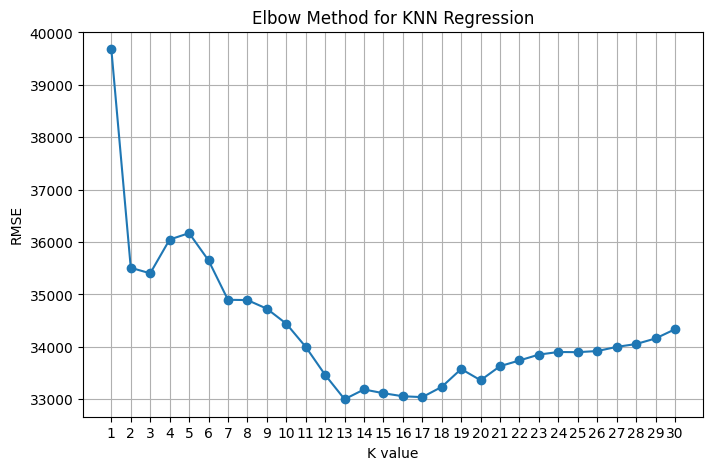

In [209]:
rmse_scores = []

k_values = range(1, 31)

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    
    y_pred_k = knn.predict(X_test_scaled)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_k))
    rmse_scores.append(rmse)


plt.figure(figsize=(8, 5))
plt.plot(k_values, rmse_scores, marker="o")

plt.xlabel("K value")
plt.ylabel("RMSE")
plt.title("Elbow Method for KNN Regression")
plt.xticks(k_values)
plt.grid(True)

plt.show()

In [210]:
best_k = k_values[np.argmin(rmse_scores)]
best_rmse = min(rmse_scores)

print("Best K:", best_k)
print("Lowest RMSE:", best_rmse)

Best K: 13
Lowest RMSE: 32999.862988778565


In [211]:
best_knn = KNeighborsRegressor(n_neighbors=best_k)

best_knn.fit(X_train_scaled, y_train)

best_y_pred = best_knn.predict(X_test_scaled)

print("Final RMSE:", np.sqrt(mean_squared_error(y_test, best_y_pred)))
print("Final MAE:", mean_absolute_error(y_test, best_y_pred))
print("Final R²:", r2_score(y_test, best_y_pred))

Final RMSE: 32999.862988778565
Final MAE: 21386.621596616442
Final R²: 0.8114262738893024


In [212]:
def triangular_weights(distances):
    """
    Stable triangular kernel weights.
    避免 k=1 或最大距离导致所有权重为 0。
    """
    distances = np.asarray(distances)
    
    eps = 1e-8
    
    max_dist = distances.max(axis=1, keepdims=True)
    
    weights = 1 - distances / (max_dist + eps)
    
    weights = np.clip(weights, eps, None)
    
    return weights


knn_triangle = KNeighborsRegressor(
    n_neighbors=5,
    metric="minkowski",
    p=2,
    weights=triangular_weights,
    n_jobs=-1
)

knn_triangle.fit(X_train_scaled, y_train)

y_pred_triangle = knn_triangle.predict(X_test_scaled)


mse_triangle = mean_squared_error(y_test, y_pred_triangle)
rmse_triangle = np.sqrt(mse_triangle)
mae_triangle = mean_absolute_error(y_test, y_pred_triangle)
r2_triangle = r2_score(y_test, y_pred_triangle)

print("Triangular KNN Evaluation")
print("MSE:", mse_triangle)
print("RMSE:", rmse_triangle)
print("MAE:", mae_triangle)
print("R²:", r2_triangle)

Triangular KNN Evaluation
MSE: 1191209522.2192304
RMSE: 34513.90331763752
MAE: 22766.32253471862
R²: 0.7937257268463734


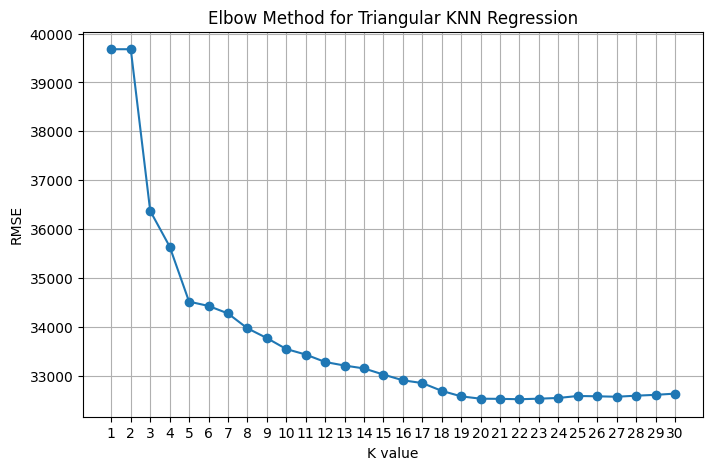

In [213]:
k_values = range(1, 31)

rmse_scores_triangle = []

for k in k_values:
    knn_triangle = KNeighborsRegressor(
        n_neighbors=k,
        metric="minkowski",
        p=2,
        weights=triangular_weights,
        n_jobs=-1
    )
    
    knn_triangle.fit(X_train_scaled, y_train)
    
    y_pred_k = knn_triangle.predict(X_test_scaled)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_k))
    
    rmse_scores_triangle.append(rmse)


plt.figure(figsize=(8, 5))
plt.plot(k_values, rmse_scores_triangle, marker="o")

plt.xlabel("K value")
plt.ylabel("RMSE")
plt.title("Elbow Method for Triangular KNN Regression")
plt.xticks(k_values)
plt.grid(True)

plt.show()

<!-- Have you learned how to write a paragraph in Markdown? If not, this is a great opportunity to do so!  -->


In [214]:
best_k_triangle = list(k_values)[np.argmin(rmse_scores_triangle)]
best_rmse_triangle = min(rmse_scores_triangle)

print("Best K for Triangular KNN:", best_k_triangle)
print("Lowest RMSE:", best_rmse_triangle)

Best K for Triangular KNN: 22
Lowest RMSE: 32517.441198813038


In [215]:
best_knn_triangle = KNeighborsRegressor(
    n_neighbors=best_k_triangle,
    metric="minkowski",
    p=2,
    weights=triangular_weights,
    n_jobs=-1
)

best_knn_triangle.fit(X_train_scaled, y_train)

best_y_pred_triangle = best_knn_triangle.predict(X_test_scaled)

print("Final Triangular KNN Evaluation")
print("RMSE:", np.sqrt(mean_squared_error(y_test, best_y_pred_triangle)))
print("MAE:", mean_absolute_error(y_test, best_y_pred_triangle))
print("R²:", r2_score(y_test, best_y_pred_triangle))

Final Triangular KNN Evaluation
RMSE: 32517.441198813038
MAE: 21302.750357394438
R²: 0.8168994553121185


In [216]:
# Find 22 nearest neighbours for ALL test observations
distances, indices = best_knn_triangle.kneighbors(
    X_test_scaled,
    n_neighbors=best_k_triangle
)

# Create 22 separate DataFrames
for i in range(best_k_triangle):

    # indices[:, i]
    # = the i-th nearest neighbour for EVERY test observation
    neighbour_original_indices = X_train.index[indices[:, i]]

    group_df = df_encoded.loc[neighbour_original_indices].copy()

    # Add information about which neighbour rank this is
    group_df["Neighbor_Rank"] = i + 1

    # Add distance
    group_df["Distance"] = distances[:, i]

    # Optional: identify which test observation this neighbour belongs to
    group_df["Test_Index"] = X_test.index

    group_df = group_df.reset_index(drop=True)

    # Create:
    # group_1_df
    # group_2_df
    # ...
    # group_22_df
    globals()[f"group_{i+1}_df"] = group_df

In [217]:
group_dfs = []
# Create a list to store each group of neighbors
for i in range(best_k_triangle):
    neighbour_original_indices = X_train.index[indices[:, i]]
    group_df = df_encoded.loc[neighbour_original_indices].copy()
    group_df["Neighbor_Rank"] = i + 1
    group_df["Distance"] = distances[:, i]
    group_df["Test_Index"] = X_test.index
    group_df = group_df.reset_index(drop=True)
    group_dfs.append(group_df)

In [218]:
# Access the first group of neighbors
group_0_df  = group_dfs[0]
group_0_df

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,PavedDrive_N,PavedDrive_P,SaleCondition_Abnorml,SaleCondition_Partial,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,Neighbor_Rank,Distance,Test_Index
0,160,36.0,2628,7,5,2003,2003,106.0,0,0,...,0,0,0,0,0,0,0,1,2.835813,969
1,60,68.0,11214,7,5,1998,1999,0.0,0,0,...,0,0,0,0,0,0,0,1,3.673834,927
2,85,75.0,11380,6,8,1966,2008,216.0,944,0,...,0,0,0,0,0,0,0,1,8.096077,978
3,80,68.0,8530,7,5,1995,1996,22.0,0,0,...,0,0,0,0,0,0,0,1,2.549825,1624
4,20,53.0,5470,3,5,1958,1958,0.0,0,0,...,0,0,0,0,0,0,0,1,3.791694,2445
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
577,50,60.0,11409,5,4,1949,2008,0.0,292,0,...,0,0,0,0,0,0,0,1,7.175578,1373
578,85,70.0,8400,5,6,1968,1968,0.0,744,0,...,0,0,0,0,0,0,0,1,7.049412,2806
579,45,50.0,6130,5,6,1924,1950,0.0,784,0,...,0,0,0,0,0,0,0,1,5.537729,2451
580,160,24.0,1733,6,6,1980,1980,0.0,0,0,...,0,0,0,0,0,0,0,1,5.771253,2560
